# Ember

From day 3 of a wildfire, Ember predicts how far each of eight compass-sector
edges will advance, in kilometres, at +24 h and +72 h. A five-qubit quantum
reservoir turns recent weather and spread history into fixed features; a
ridge read-out learns the forecasts. Data: CWFIS hotspots and fire perimeters,
Canadian Forest Service.

This notebook reads the committed results and runs two small local checks.
It needs no downloads. Install `requirements.txt`, select the project Python
environment, and run all cells from the repository root or `notebooks/`.

In [1]:
from pathlib import Path
import json
import os
import sys

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
assert (root / "ember" / "reservoir.py").is_file(), "Run from the repository root or notebooks/"
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from ember.hardware import frozen_reservoir
from ember.metrics import mae
from ember.reservoir import feature_names

pd.set_option("display.max_rows", 50)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

def read_json(path):
    return json.loads(Path(path).read_text())

def show_figure(name):
    display(Image(filename=str(Path("figures") / name), width=950, embed=True))

print("Committed results loaded locally; distances and errors are in km.")

Committed results loaded locally; distances and errors are in km.


## Data and sector geometry

Years stay separate: train on 2018–2021, choose settings on 2022 validation,
and score 2023 test fires once. Counts below come from `results/fire_counts.json`.
Each fire has eight sectors, numbered clockwise from north.

The day-1 seed is the largest cluster of detections linked within 2 km.
Later growth follows chains within 2 km of the existing fire; daily radial
advance is capped at 30 km. The target in sector $k$ is
$$y_k^{(h)}(t)=r_k(t+h)-r_k(t),\qquad h\in\{1,3\}\text{ days}.$$
E10 checks the rebuilt final outline against the official final perimeter.

In [2]:
counts = pd.DataFrame.from_dict(read_json("results/fire_counts.json"), orient="index")
counts.index.name = "year"
display(counts[["split", "fires", "sector_rows", "origin_days"]])
display(counts.groupby("split", sort=False)[["fires"]].sum())
rebuild = read_json("results/e10_2023.json")
print(f"E10 median IoU, eight-point outline: {rebuild['median_iou']:.6f}")
print(f"E10 median IoU, buffered hotspots: {rebuild['median_iou_buffered']:.6f}")

,split,fires,sector_rows,origin_days
year,,,,
2018,train,134,43824,5076
2019,train,44,17200,2018
2020,train,7,1816,206
2021,train,193,63464,7354
2022,val,102,40552,4763
2023,test,392,171392,20248


,fires
split,
train,378
val,102
test,392


E10 median IoU, eight-point outline: 0.650093
E10 median IoU, buffered hotspots: 0.827641


## Quantum reservoir

E3 selected the window length, encoding scale, input map and ridge penalties
on validation. The circuit gates stay fixed; only the read-out is trained.
Training rows set the input min/max scaling to $[0,1]$.
Each window starts in $|00000\rangle$ and carries its state through the days:
input-dependent RY rotations, a CZ chain, then fixed RY/RZ rotations.
The saved ZF015 windows are already scaled. Below are the frozen choices,
the first window's circuit, and all observable names in read-out order.

In [3]:
frozen = read_json("results/frozen_config.json")
choices = {key: frozen[key] for key in ("L", "gamma", "input_map", "lambdas", "reservoir_seed")}
print(json.dumps(choices, indent=2))
reservoir = frozen_reservoir("results/frozen_config.json")
with np.load("hardware/zf015_case.npz", allow_pickle=False) as case:
    W = case["windows"].copy()
    case_rows = pd.DataFrame({
        "date": pd.to_datetime(case["dates"]),
        "sector": case["sectors"],
    })
assert W.shape == (88, 5, 5)
print("ZF015 window archive shape:", W.shape)
print(reservoir.circuit(W[0]).draw("text", fold=110))
names = feature_names(reservoir.n)
assert len(names) == 20
print("Feature names (20):", ", ".join(names))

{
  "L": 5,
  "gamma": 0.7853981633974483,
  "input_map": [
    "w_k",
    "isi",
    "dd_km",
    "bui",
    "rh"
  ],
  "lambdas": {
    "1": 1e-06,
    "3": 1e-06
  },
  "reservoir_seed": 7
}
ZF015 window archive shape: (88, 5, 5)
      ┌─────────────┐    ┌────────────┐┌──────────────┐┌─────────────┐                               »
q_0: ─┤ Ry(0.45246) ├──■─┤ Ry(5.4887) ├┤ Rz(0.033083) ├┤ Ry(0.49162) ├───────────────────────■───────»
     ┌┴─────────────┴┐ │ └────────────┘└┬────────────┬┘└┬────────────┤┌───────────────┐      │       »
q_1: ┤ Ry(0.0043449) ├─■───────■────────┤ Ry(5.1599) ├──┤ Rz(5.0081) ├┤ Ry(0.0055294) ├──────■───────»
     └───┬───────┬───┘         │        └────────────┘  ├────────────┤└─┬───────────┬─┘  ┌───────┐   »
q_2: ────┤ Ry(0) ├─────────────■──────────────■─────────┤ Ry(2.9401) ├──┤ Rz(1.904) ├────┤ Ry(0) ├───»
       ┌─┴───────┴──┐                         │         └────────────┘  ├───────────┴┐ ┌─┴───────┴──┐»
q_3: ──┤ Ry(0.4308) ├────────────────────────

In [4]:
numpy_features = reservoir.feature_matrix(W[:2], mode="numpy")
exact_features = reservoir.feature_matrix(W[:2], mode="exact")
max_diff = float(np.max(np.abs(numpy_features - exact_features)))
print(f"NumPy / exact feature max difference: {max_diff:.12e}")
assert max_diff <= 1e-10

NumPy / exact feature max difference: 7.771561172376e-16


## Baselines

- Persistence: $h$ times today's sector advance.
- Mean: the mean target advance in training rows, separately for each lead.
- FBP physics: $h\cdot\mathrm{ros}\cdot T_b/1000\cdot\max(0,w_k/\mathrm{ws})$;
  $T_b$ is burning minutes per day fitted on train, ros is in m/min, and calm wind gives zero.
- Raw-window ridge: ridge regression on the same raw input history.
- ESN 5/20: fully connected tanh reservoirs with 5 or 20 units and a ridge read-out.
- Random (Haar) circuit: the same encoding and read-out with random two-qubit entanglers.
- Reservoir + raw: ridge on reservoir features together with the raw window.

## Test 2023 results

E1 uses exact noiseless features. MAE and growing-sector MAE are in km;
growing means the target advance is positive. Skill is relative to persistence
(positive is better). IoU measures predicted versus observed outline overlap
(higher is better). Intervals are 95% fire-bootstrap intervals.
The Haar row averages per-seed metrics and interval endpoints; it is not an
ensemble confidence interval. E7 is the reservoir + raw row.

,model,lead_h,"mae [mae_lo, mae_hi]",skill,iou,mae_growing
0,esn20,24,"0.350293 [0.322225, 0.376369]",-0.003746,0.762824,1.429400
1,esn5,24,"0.357794 [0.330522, 0.383042]",-0.025237,0.757984,1.473719
2,fbp,24,"0.261797 [0.232591, 0.288843]",0.249836,0.781474,1.593038
3,haar,24,"0.360574 [0.332342, 0.386820]",-0.033203,0.760518,1.446067
4,mean,24,"0.387043 [0.359699, 0.412127]",-0.109049,0.749887,1.495680
5,persistence,24,"0.348986 [0.306802, 0.388743]",0.000000,0.917901,1.705278
6,qrc,24,"0.359898 [0.330036, 0.387195]",-0.031268,0.757289,1.455600
7,qrc_raw,24,"0.347457 [0.317997, 0.374092]",0.004380,0.765207,1.420634
8,raw,24,"0.348129 [0.319236, 0.374964]",0.002455,0.766076,1.424595
9,esn20,72,"0.934348 [0.857983, 1.004096]",0.126603,0.668843,2.364160


Paired MAE differences: reservoir minus reference; negative favours the reservoir.


,reference,qrc_minus_reference_mae,difference_lo,difference_hi,lead_h
0,persistence,0.010912,-0.004148,0.025118,24
1,raw,0.011769,0.009486,0.014071,24
2,esn20,0.009605,0.005998,0.012999,24
3,persistence,-0.127143,-0.185652,-0.067169,72
4,raw,0.022938,0.016652,0.028777,72
5,esn20,0.008295,-0.002300,0.017653,72


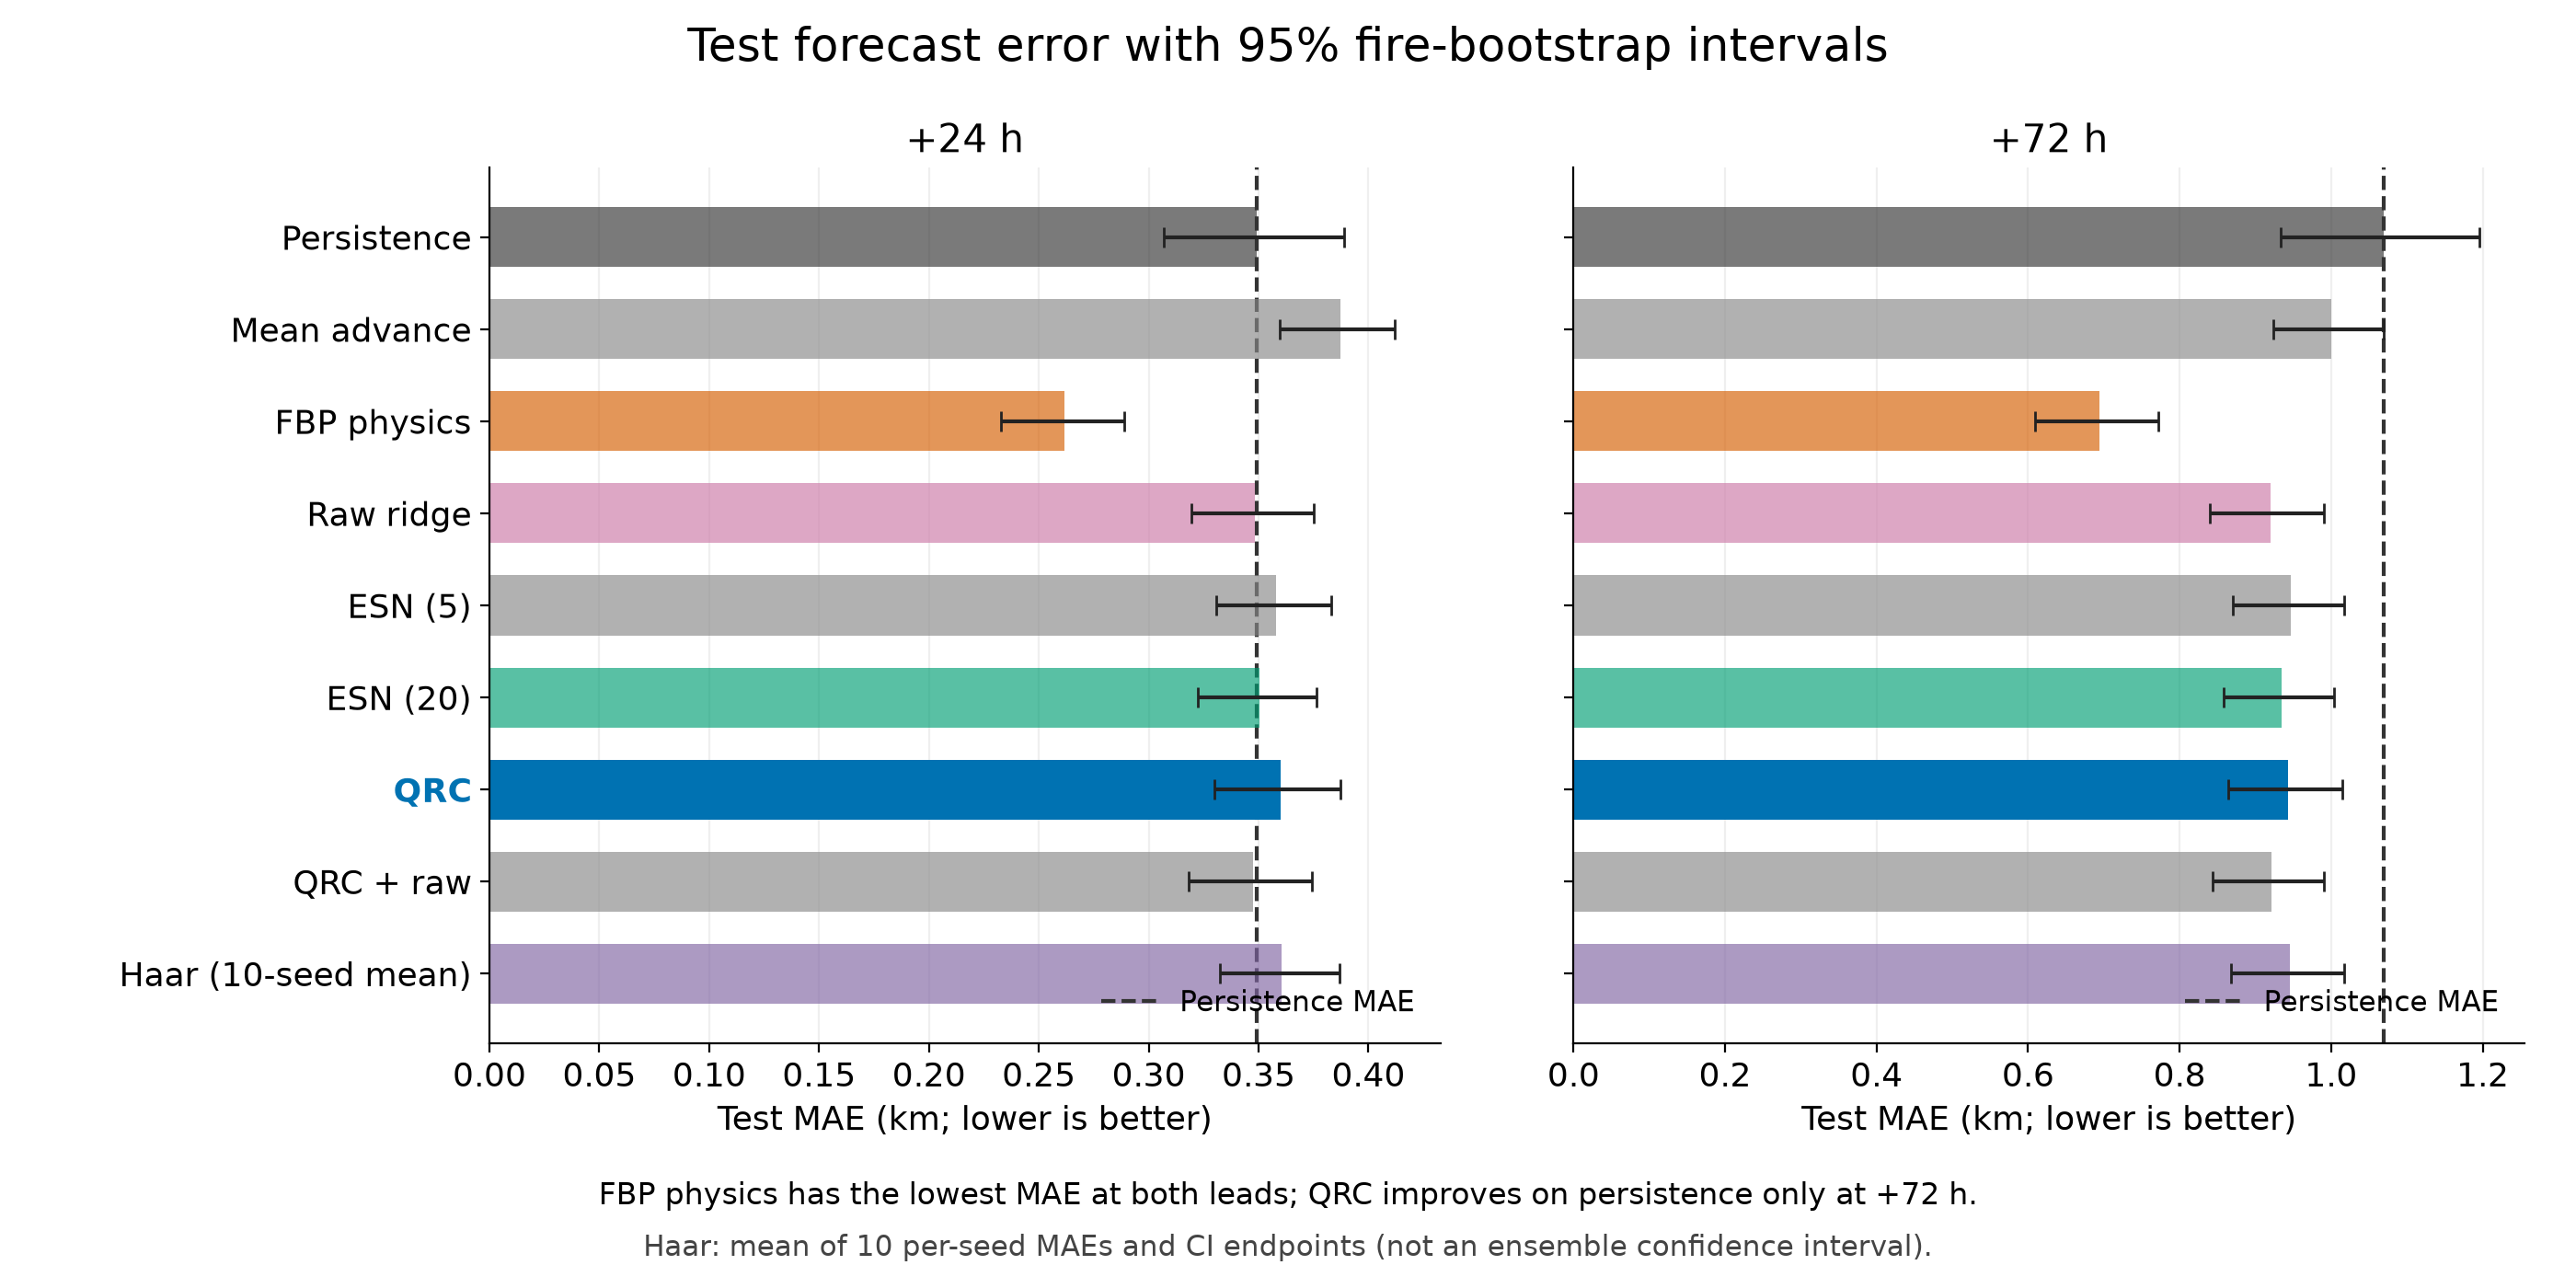

In [5]:
metrics = pd.read_csv("results/metrics.csv")
test = metrics.loc[metrics.split.eq("test")].copy()
result_table = test[["model", "lead", "skill", "iou", "mae_growing"]].copy()
result_table["lead"] *= 24
result_table = result_table.rename(columns={"lead": "lead_h"})
result_table.insert(2, "mae [mae_lo, mae_hi]", [
    f"{row.mae:.6f} [{row.mae_lo:.6f}, {row.mae_hi:.6f}]"
    for row in test.itertuples()
])
display(result_table.sort_values(["lead_h", "model"]).reset_index(drop=True))
comparisons = pd.read_csv("results/qrc_comparisons.csv")
comparisons["lead_h"] = comparisons.pop("lead") * 24
print("Paired MAE differences: reservoir minus reference; negative favours the reservoir.")
display(comparisons)
show_figure("e1_test_mae.png")

## Controls

E4 varies fixed circuit seeds; the table gives mean and sample standard
deviation of test MAE. E2 splits sectors by wind direction. E5 varies local
simulator shots and noise on the saved subset, with its exact MAE alongside.
E9 drops hotspot days and carries the last value forward. These checks use
the committed tables and keep the selected configuration fixed.

E4 — fixed-seed test MAE (km)


seeds  mae_mean   mae_sd
model lead                          
haar  1        10  0.360574 0.007301
      3        10  0.945931 0.015459
qrc   1         5  0.362390 0.008139
      3         5  0.949891 0.016248

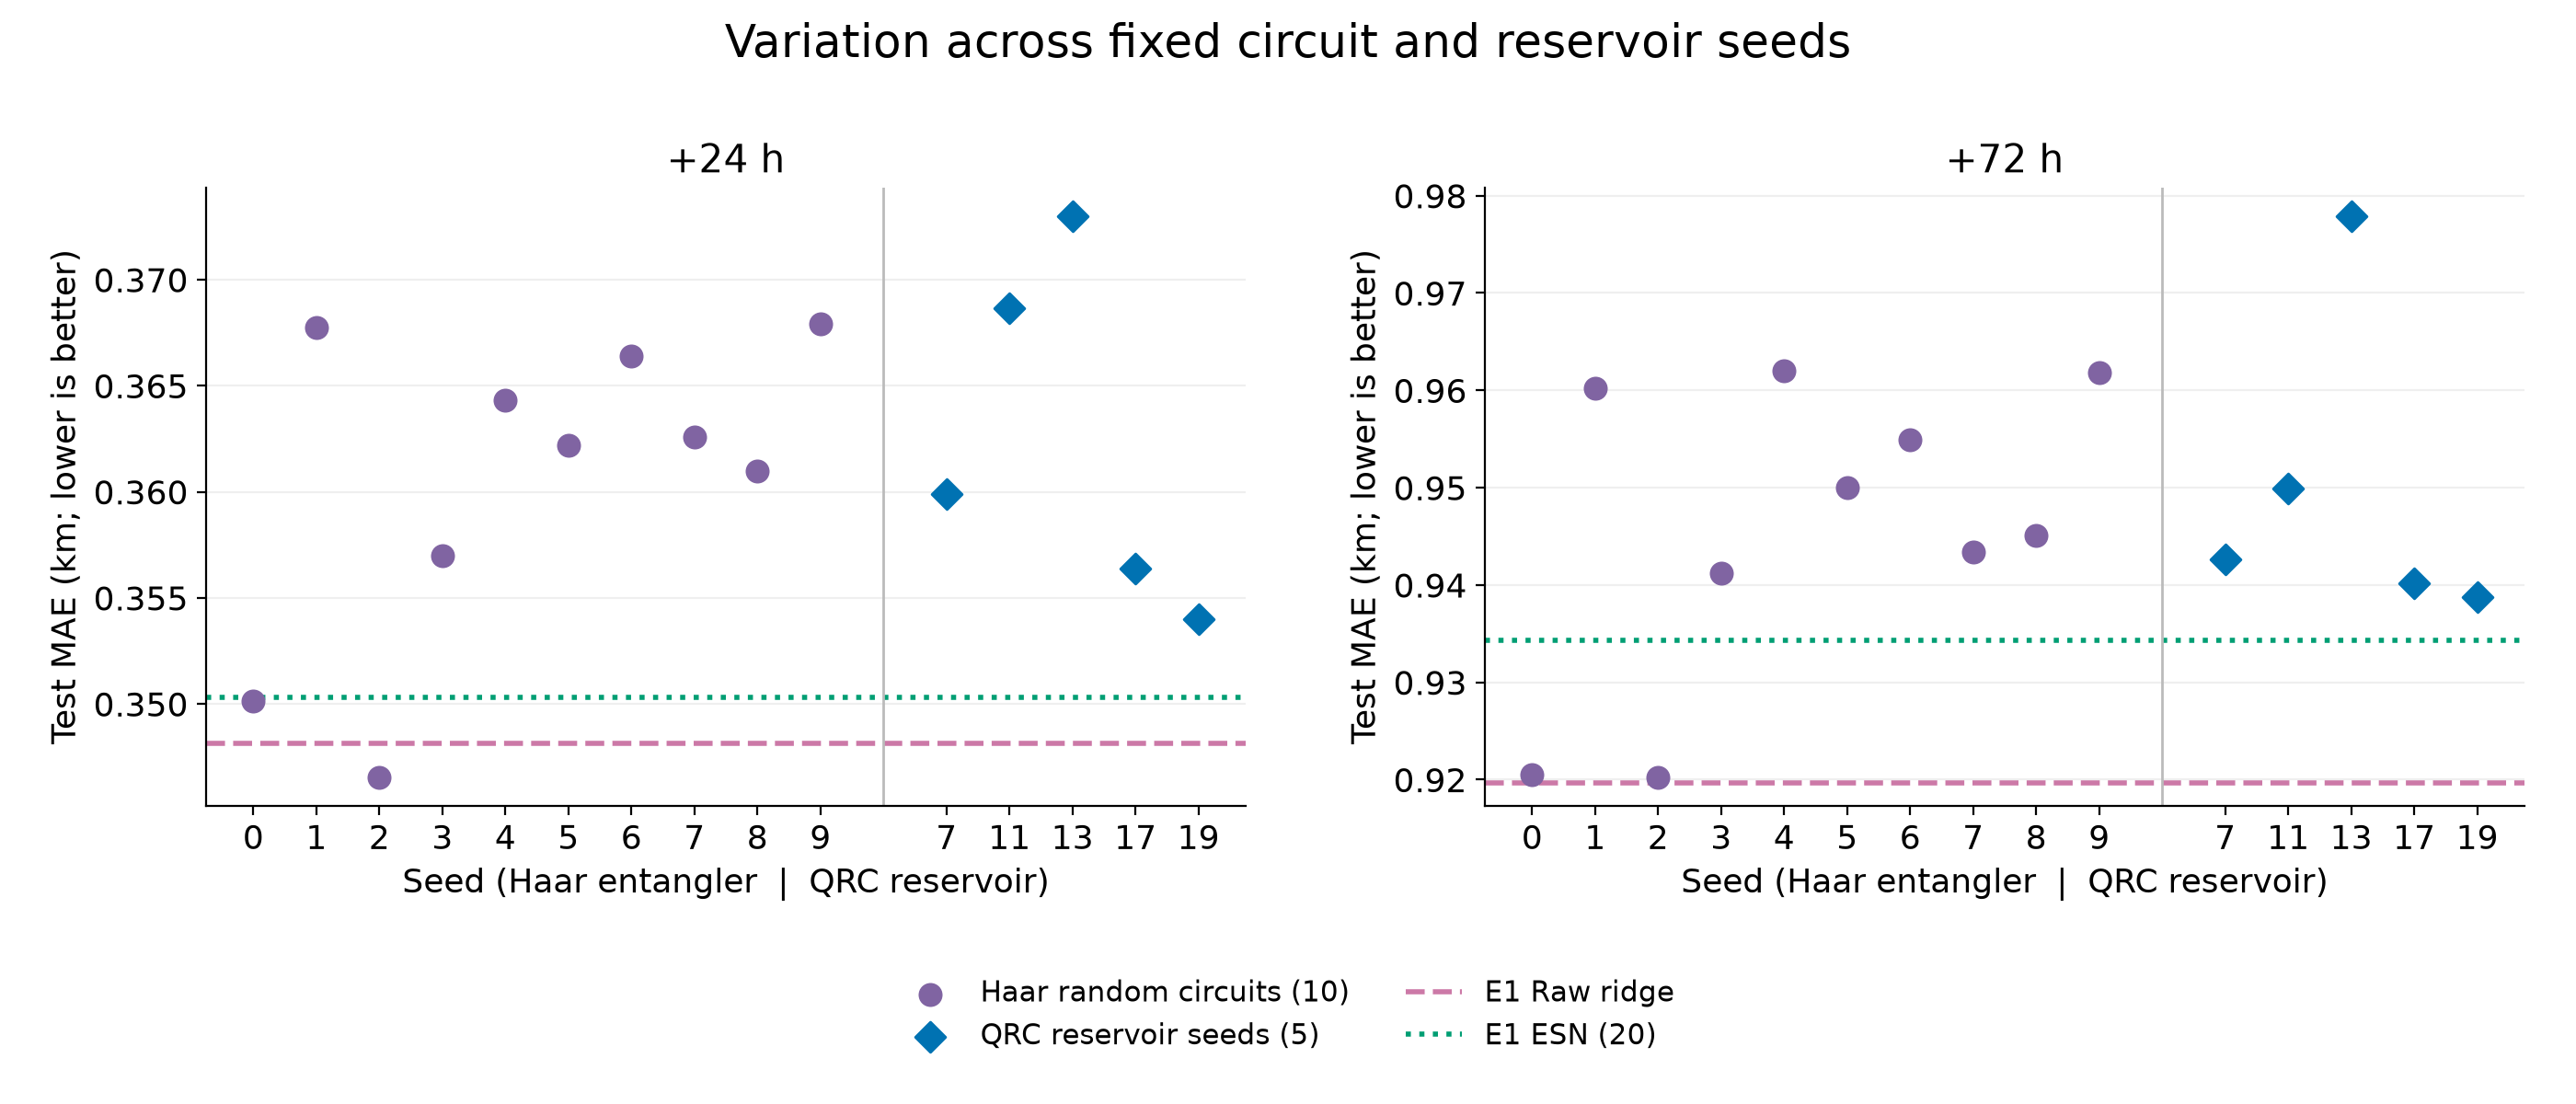

E2 — test MAE by wind bin (km); lead is in days


lead                         1        3
model       wind_bin                   
esn20       crosswind 0.322775 0.898927
            downwind  0.460195 1.076083
            upwind    0.267708 0.827765
fbp         crosswind 0.208375 0.607898
            downwind  0.405191 0.919101
            upwind    0.171419 0.554627
persistence crosswind 0.325135 1.004476
            downwind  0.444562 1.302125
            upwind    0.277086 0.902258
qrc         crosswind 0.334649 0.908947
            downwind  0.457917 1.069567
            upwind    0.286944 0.849157

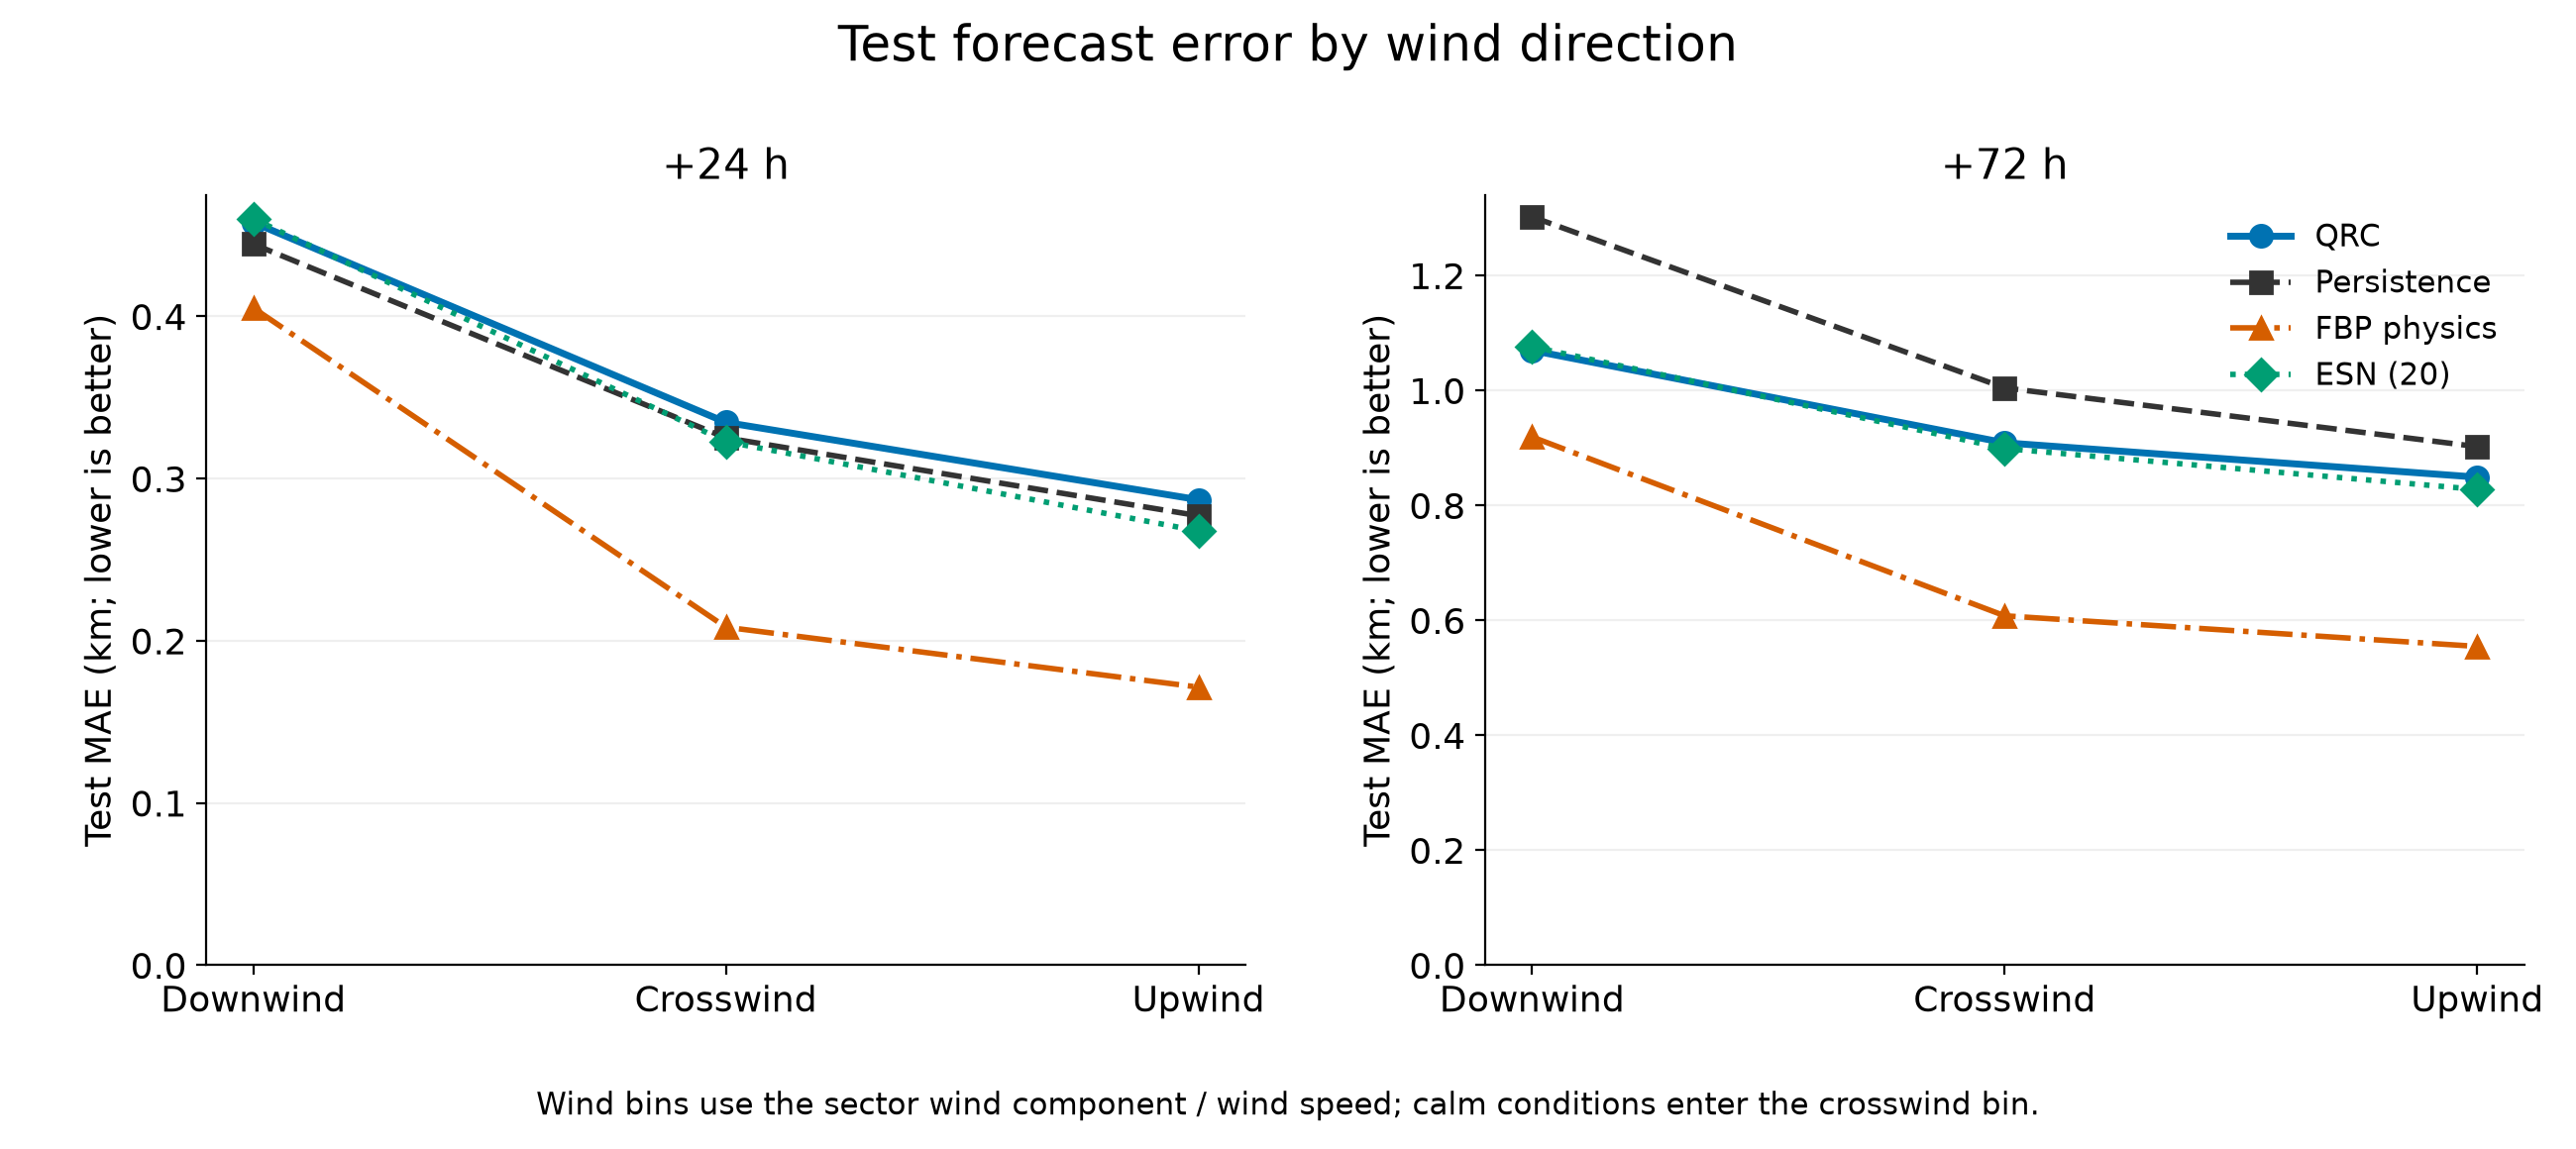

In [6]:
seeds = pd.read_csv("results/e4_seeds.csv")
seeds = seeds.loc[seeds.split.eq("test")]
print("E4 — fixed-seed test MAE (km)")
display(seeds.groupby(["model", "lead"]).agg(
    seeds=("seed", "nunique"), mae_mean=("mae", "mean"), mae_sd=("mae", "std")
))
show_figure("e4_seeds.png")

wind = pd.read_csv("results/e2_wind.csv")
print("E2 — test MAE by wind bin (km); lead is in days")
display(wind.pivot(index=["model", "wind_bin"], columns="lead", values="mae"))
show_figure("e2_wind.png")

In [7]:
shots = pd.read_csv("results/e5_shots.csv")
print("E5 — sampled / exact MAE (km) on the same subset; lead is in days")
display(shots.pivot(index=["shots", "noise"], columns="lead", values=["mae", "mae_exact", "n_rows"]))

sparse = pd.read_csv("results/e9_sparse.csv")
print("E9 — test MAE (km) as hotspot days are removed; lead is in days")
display(sparse.pivot(index=["drop_frac", "model"], columns="lead", values="mae"))

E5 — sampled / exact MAE (km) on the same subset; lead is in days


mae          mae_exact               n_rows            
lead                  1        3         1        3           1           3
shots noise                                                                
100   fake_fez 1.227445 2.863999  0.359182 0.933964 2036.000000 1953.000000
      ideal    1.212296 2.824454  0.359182 0.933964 2036.000000 1953.000000
1000  fake_fez 0.521288 1.296415  0.359182 0.933964 2036.000000 1953.000000
      ideal    0.587455 1.400993  0.359182 0.933964 2036.000000 1953.000000
2000  fake_fez 0.453460 1.143627  0.359182 0.933964 2036.000000 1953.000000
      ideal    0.503036 1.226322  0.359182 0.933964 2036.000000 1953.000000
10000 fake_fez 0.336619 0.905716  0.359182 0.933964 2036.000000 1953.000000
      ideal    0.405059 1.011671  0.359182 0.933964 2036.000000 1953.000000

E9 — test MAE (km) as hotspot days are removed; lead is in days


lead                         1        3
drop_frac model                        
0.000000  esn20       0.350293 0.934348
          fbp         0.261797 0.694097
          persistence 0.348986 1.069785
          qrc         0.359898 0.942642
0.150000  esn20       0.377358 0.983962
          fbp         0.271845 0.717393
          persistence 0.394420 1.160988
          qrc         0.384278 0.989753
0.300000  esn20       0.384959 1.014235
          fbp         0.266770 0.725146
          persistence 0.441546 1.299062
          qrc         0.384490 1.007522
0.450000  esn20       0.344167 0.910056
          fbp         0.230404 0.648513
          persistence 0.439432 1.294322
          qrc         0.347080 0.925718

## Real hardware (E6)

The saved job ran Z-basis circuits on ibm_fez. The table below compares its
features with exact simulation, local FakeFez simulation and persistence.
All feature sources use the same frozen, exact-trained Z-only read-out.
This is one fire with 88 correlated sector windows: the comparison is descriptive.

For the local recomputation, targets come from `results/e6_predictions.csv`
and are joined by date and sector to `hardware/zf015_case.npz` archive order.
The saved scaler maps raw inputs before circuit encoding; the hardware file
already contains measured Z/ZZ features, so these go directly into the saved
ridge coefficients and intercept, followed by the saved lower clipping bound.

In [8]:
job_metrics = read_json("hardware/e6_job_metrics.json")
meta = read_json("results/e6_meta.json")
jobs = read_json("hardware/jobs.json")
job = next(row for row in jobs if row["job_id"] == job_metrics["job_id"])
assert meta["job_id"] == job["job_id"]
assert meta["backend"] == job["backend"]
assert meta["shots"] == job["budget"]["shots"]
display(pd.DataFrame([{
    "job_id": job_metrics["job_id"],
    "backend": meta["backend"],
    "shots_per_circuit": meta["shots"],
    "circuits": len(W),
    "qpu_seconds": job_metrics["usage"]["qpu_charge_time_seconds"],
}]))

,job_id,backend,shots_per_circuit,circuits,qpu_seconds
0,dbm0tm58ft8s738tu920,ibm_fez,10000,88,238


E6 +24 h absolute MAE difference: 0.000000000000e+00 km
E6 +72 h absolute MAE difference: 0.000000000000e+00 km


,lead_h,recomputed_mae,saved_mae,absolute_difference
0,24,0.257881,0.257881,0.000000
1,72,0.979314,0.979314,0.000000


,source,lead,mae,n_rows,feature_mae
0,exact,1,0.272408,88,0.000000
1,fake_fez,1,0.277193,88,0.043793
2,hardware,1,0.257881,88,0.072526
3,persistence,1,0.300678,88,NaN
4,exact,3,1.001495,88,0.000000
5,fake_fez,3,1.005559,88,0.043793
6,hardware,3,0.979314,88,0.072526
7,persistence,3,1.228193,88,NaN


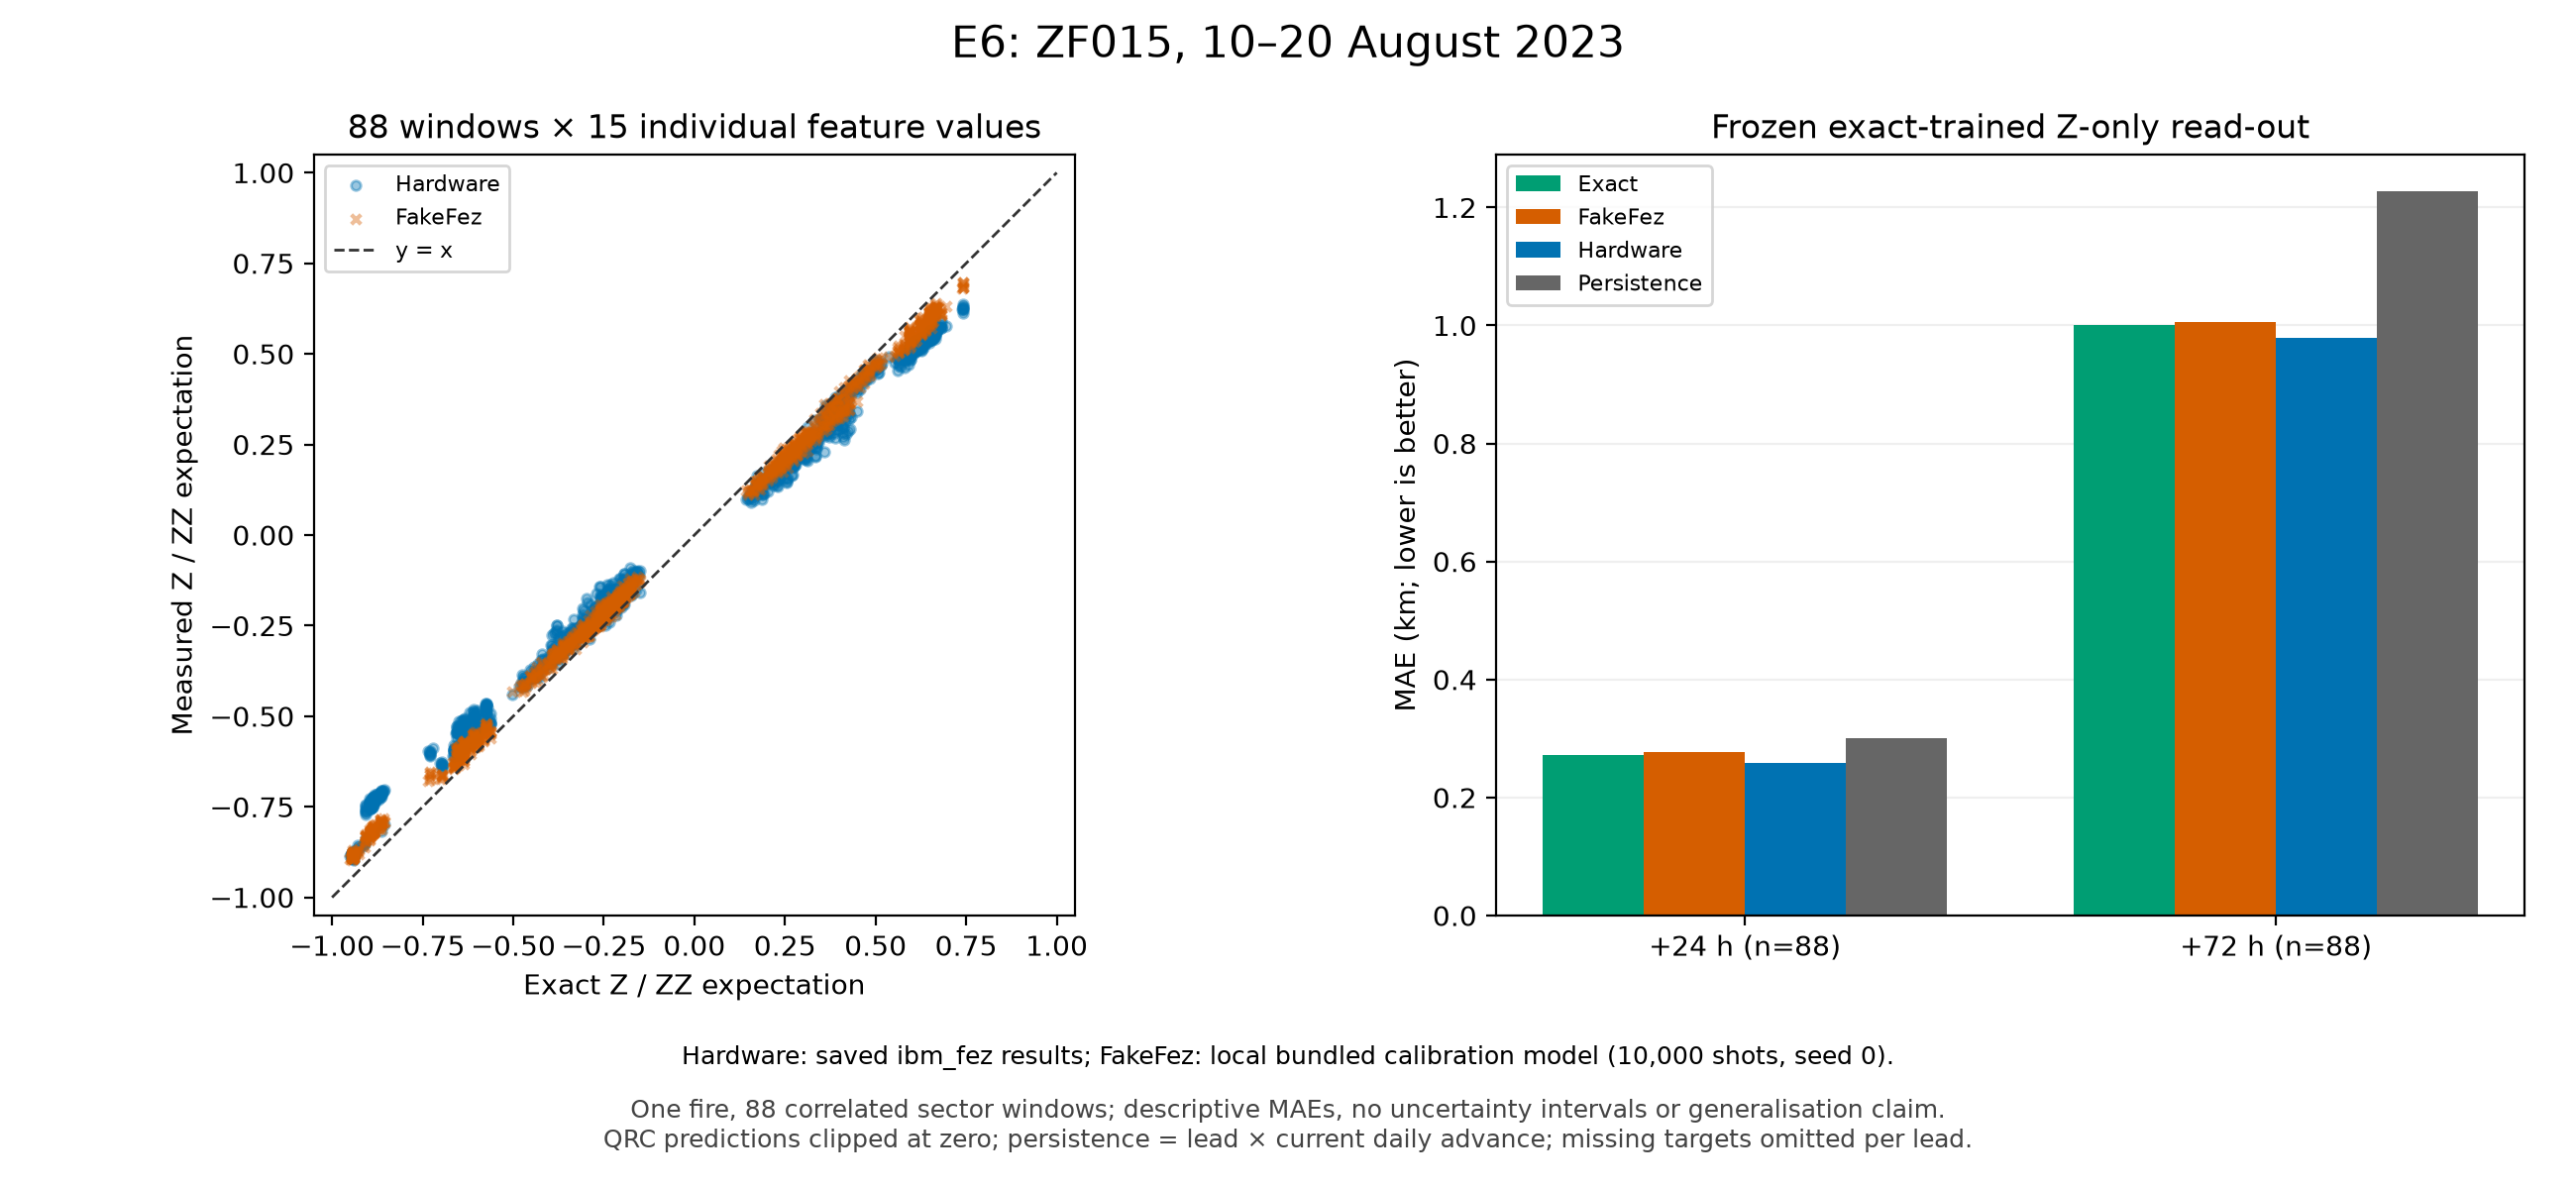

In [9]:
# E6 live recomputation from measured features and frozen weights.
readout = read_json("results/qrc_z_readout.json")
measured = np.load("hardware/e6_hw_features.npy", allow_pickle=False)
assert measured.shape == (len(W), len(readout["feature_names"]))
assert readout["feature_names"] == names[:measured.shape[1]]
assert np.isfinite(measured).all()
assert np.all((W >= 0) & (W <= 1))
assert len(readout["scaler"]["lo"]) == W.shape[-1]
saved_predictions = pd.read_csv("results/e6_predictions.csv", parse_dates=["date"])
hardware_scores = pd.read_csv("results/e6_hardware.csv")
checks = []
for lead in (1, 3):
    fit = readout["readouts"][str(lead)]
    predicted = np.maximum(
        measured @ np.asarray(fit["coefficients"]) + fit["intercept"],
        readout["prediction_clip_min"],
    )
    targets = saved_predictions.loc[saved_predictions.lead.eq(lead), ["date", "sector", "y"]]
    joined = case_rows.assign(yhat=predicted).merge(
        targets, on=["date", "sector"], how="left", sort=False, validate="one_to_one"
    )
    keep = joined.y.notna()
    reference = hardware_scores.loc[
        hardware_scores.source.eq("hardware") & hardware_scores.lead.eq(lead)
    ].iloc[0]
    assert int(keep.sum()) == int(reference.n_rows)
    recomputed = mae(joined.loc[keep, "y"], joined.loc[keep, "yhat"])
    difference = abs(recomputed - reference.mae)
    print(f"E6 +{lead * 24} h absolute MAE difference: {difference:.12e} km")
    assert difference < 1e-9
    checks.append({"lead_h": lead * 24, "recomputed_mae": recomputed,
                   "saved_mae": reference.mae, "absolute_difference": difference})
display(pd.DataFrame(checks))
display(hardware_scores)
show_figure("e6_hardware.png")

## ZF015 / Yellowknife case

The map compares dated reconstructed outlines and forecasts with the official
season-end perimeter. Yellowknife's centre distance and sector below come from
`results/e8_eta.json`. The single-sector time-to-reach is not meaningful here:
the closest approach is through the south lobe, sector 4, about 25 km away.
A single-sector time-to-reach is not reported.

Yellowknife: 66.7 km from the fire centre, sector 3.


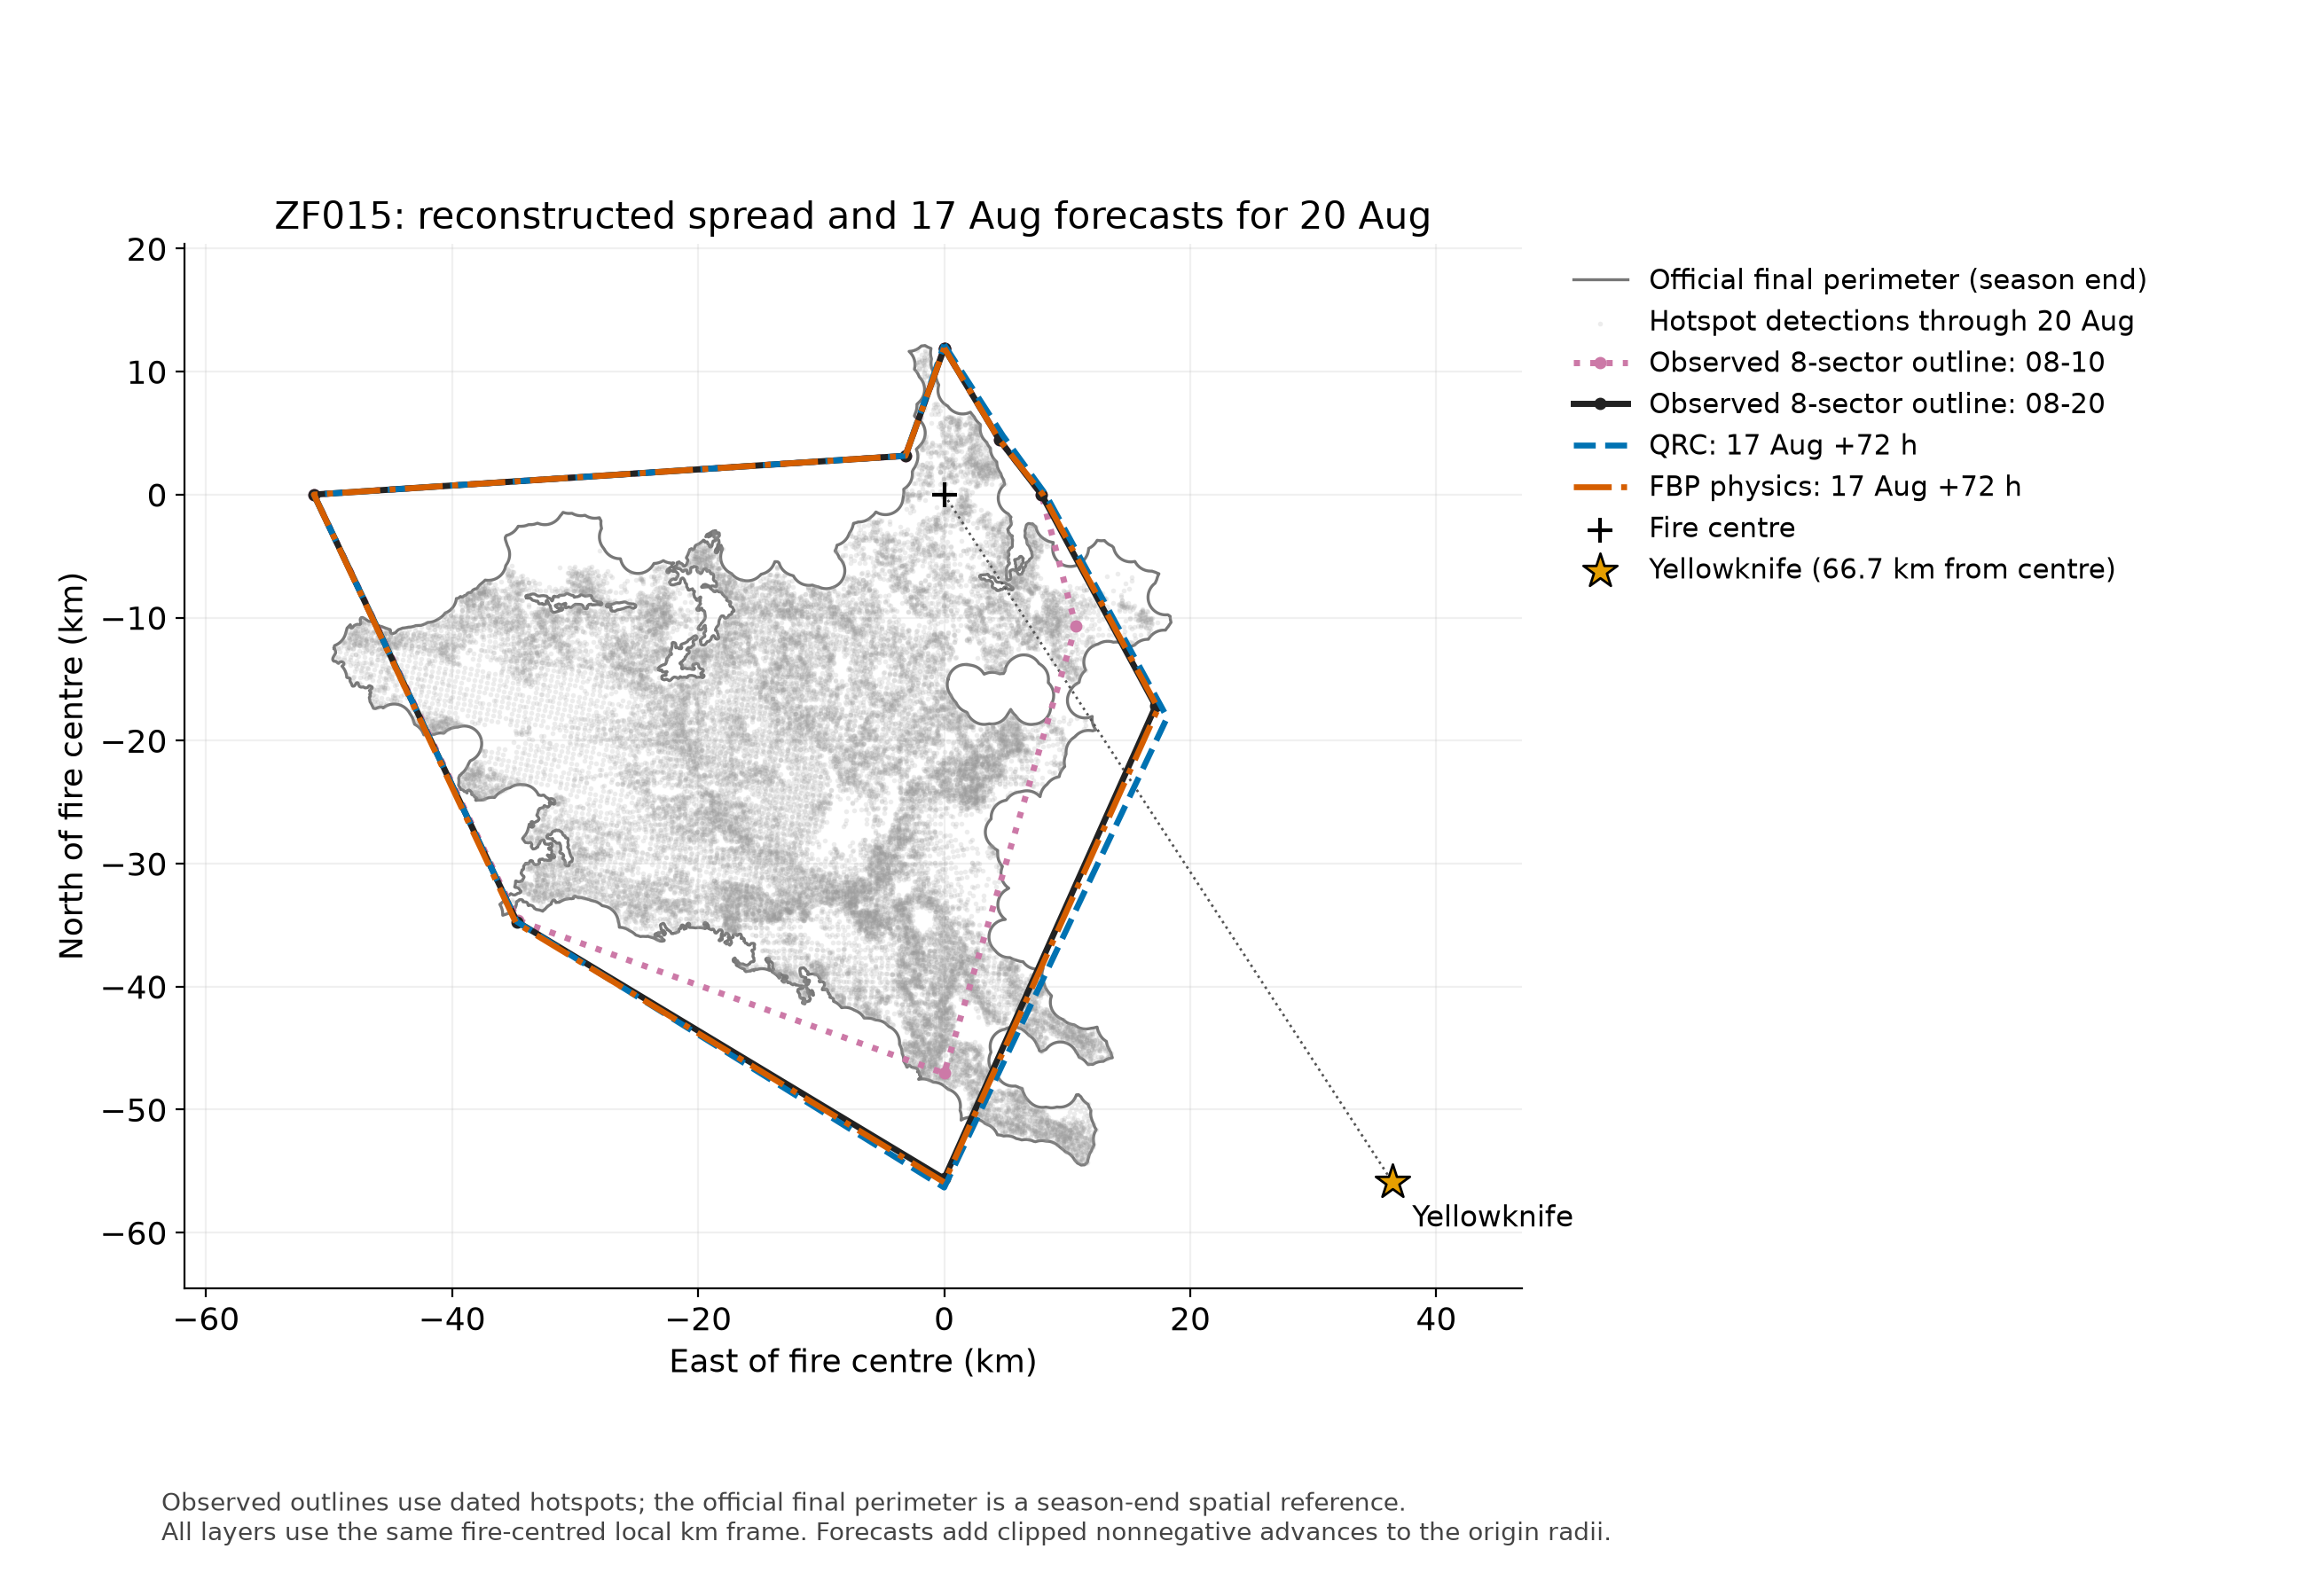

In [10]:
location = read_json("results/e8_eta.json")
print(f"{location['town']}: {location['distance_km']:.1f} km from the fire centre, sector {location['sector']}.")
show_figure("e8_zf015_map.png")

## Conclusions and limits

- On 2023 test fires the quantum reservoir is about level with classical reservoirs
  and a random circuit, slightly behind ridge on the raw inputs. No quantum advantage is claimed.
- No model wins every measure: FBP physics has the lowest mean error; persistence
  has the best outline overlap (most sectors do not move); on growing sectors
  all learned models beat FBP and persistence.
- The reservoir beats persistence only at +72 h.
- On real ibm_fez hardware the forecasts survive the noise: MAE within about
  0.02 km of the exact simulation on one fire (88 correlated windows; descriptive only).
- Limits: one hardware case; the 30 km/day cap can creep for merged fires;
  inputs exclude fuel type, which FBP uses.

### Reproduce

To rebuild the full experiment, provide the source data described in the
README (Data section), then run these scripts in order from the repository root:

1. `scripts/build_sectors.py`
2. `scripts/run_experiments.py`
3. `scripts/run_u5b.py`
4. `scripts/make_figures.py`
5. `scripts/e6_hardware.py`
6. `scripts/build_notebook.py`

Run each with `.venv/bin/python -I`. The E6 script reads the saved hardware
features. To reproduce just this notebook in a fresh clone, install
`requirements.txt` and run `.venv/bin/python -I scripts/build_notebook.py`;
all notebook inputs are committed.